# Financial sentiment with few labels

In [ ]:
# Load the project. USE_DRIVE = False uploads the zip (no Google Drive access needed).
# USE_DRIVE = True keeps the project in My Drive/finsent-project instead, which survives disconnects.
USE_DRIVE = False

import os
os.environ['TRANSFORMERS_VERBOSITY'] = 'error'          # hide the long "LOAD REPORT" tables
os.environ['HF_HUB_VERBOSITY'] = 'error'                # hide the "unauthenticated requests" notice
os.environ['PYTHONWARNINGS'] = 'ignore::UserWarning'    # hide the harmless learning-rate scheduler warning

if USE_DRIVE:
    from google.colab import drive
    drive.mount('/content/drive')
    PROJECT = '/content/drive/MyDrive/finsent-project'
else:
    PROJECT = '/content/finsent-project'
    if not os.path.exists(PROJECT):
        from google.colab import files
        uploaded = files.upload()                      # choose finsent-project.zip
        zip_name = next(iter(uploaded))
        !unzip -q -o "{zip_name}" -d /content
%cd {PROJECT}
!nvidia-smi --query-gpu=name,memory.total --format=csv

Saving finsent-project.zip to finsent-project.zip
/content/finsent-project
name, memory.total [MiB]
Tesla T4, 15360 MiB


In [ ]:
# Install anything that's missing, then record the exact versions used (for the README / report)
!pip install -q -r requirements.txt
!pip freeze > requirements-colab.txt
!python -c "import torch, transformers; print('torch', torch.__version__, '| transformers', transformers.__version__)"

torch 2.11.0+cu130 | transformers 5.21.0


## Step 1 · Prepare the data (once)

Downloads Financial PhraseBank (about 0.7 MB), removes duplicate sentences, records how strongly the annotators agreed on each label, and makes the fixed train / validation / test split. If the split already exists, it is kept: never re-split once experiments have started.

In [ ]:
if os.path.exists('data/phrasebank_clean.csv'):
    print('The split already exists, so it is kept:\n')
    print(open('data/split_summary.txt').read())
else:
    !python src/prepare_data.py

The split already exists, so it is kept:

Financial PhraseBank after cleaning

lines in 50agree file: 4846
exact duplicates dropped: 8
sentences with conflicting labels dropped: 2
unique sentences kept: 4836
groups of near-identical sentences (differ only in numbers): 22, covering 52 sentences

Sentences per split and label:
label  negative  neutral  positive   All
split                                   
test        121      575       272   968
train       423     2009       952  3384
val          60      287       137   484
All         604     2871      1361  4836

Sentences per split and agreement level (% of annotators who agreed):
agreement   50   66    75   100   All
split                                
test       130  142   244   452   968
train      429  538   814  1603  3384
val         68   81   131   204   484
All        627  761  1189  2259  4836



## Step 2 · Choose the learning rate (validation set only)

Each model, learning rate and budget is tried with 3 seeds because one seed is too noisy to choose between learning rates. Runs that already exist (seed 0 from before) are skipped. Only the validation set is used, so the test set stays sealed. Copy the suggestion at the bottom into BEST_LR in Step 3.

In [ ]:
for model in ['bert', 'finbert']:
    for lr in ['2e-5', '5e-5']:
        for n in ['200', 'all']:
            for seed in [0, 1, 2]:
                !python src/train.py --stage lrcheck --model {model} --lr {lr} --n_labels {n} --seed {seed}
!python src/analyze.py --lr_check

tokenizer_config.json: 100% 48.0/48.0 [00:00<00:00, 214kB/s]
vocab.txt: 100% 232k/232k [00:00<00:00, 36.1MB/s]
tokenizer.json: 100% 466k/466k [00:00<00:00, 90.1MB/s]
config.json: 100% 570/570 [00:00<00:00, 2.82MB/s]

model.safetensors: downloading bytes:  61% 269M/440M [00:01<00:00, 233MB/s, 23.3MB/s  ]
model.safetensors: downloading bytes:  69% 303M/440M [00:02<00:00, 171MB/s, 26.8MB/s  ]
model.safetensors: downloading bytes:  89% 394M/440M [00:02<00:00, 204MB/s, 32.8MB/s  ]
model.safetensors: reconstructing file:  76% 335M/440M [00:02<00:00, 140MB/s, 25.0MB/s  ]
model.safetensors: downloading bytes: 100% 415M/415M [00:02<00:00, 144MB/s, 36.2MB/s  ]
model.safetensors: reconstructing file: 100% 440M/440M [00:02<00:00, 153MB/s, 39.8MB/s  ]
Loading weights: 100% 197/197 [00:00<00:00, 8930.22it/s]
bert n=200 seed=0 lr=2e-05: val macro-F1 0.535 (10s, 100 steps)
Loading weights: 100% 197/197 [00:00<00:00, 6303.33it/s]
bert n=200 seed=1 lr=2e-05: val macro-F1 0.579 (9s, 100 steps)
Loading we

## Step 3 · Main experiment

2 models × 6 label budgets × 5 seeds = 60 runs, about 35 minutes on a T4. These go into a new folder, `results_main`, so they never mix with the initial 2e-5 runs in `results/`.

If Step 2 suggests 2e-5 for both models, the first runs already are the main results so you can skip Steps 3 and 4, set `RESULTS, FIGURES = 'results', 'figures'`, and go to Step 5.

In [ ]:
BEST_LR = {'bert': '2e-5', 'finbert': '2e-5'}       # replace with the suggestion from Step 2
RESULTS, FIGURES = 'results_main', 'figures_main'
BUDGETS = ['50', '100', '200', '400', '800', 'all']
SEEDS = [0, 1, 2, 3, 4]

for seed in SEEDS:
    for n in BUDGETS:
        for model in ['bert', 'finbert']:
            lr = BEST_LR[model]
            !python src/train.py --model {model} --lr {lr} --n_labels {n} --seed {seed} --results_dir {RESULTS}

Loading weights: 100% 197/197 [00:00<00:00, 5196.45it/s]
bert n=50 seed=0 lr=5e-05: val macro-F1 0.489, test macro-F1 0.458 (9s, 100 steps)
Loading weights: 100% 197/197 [00:00<00:00, 27179.30it/s]
finbert n=50 seed=0 lr=5e-05: val macro-F1 0.549, test macro-F1 0.503 (10s, 100 steps)
Loading weights: 100% 197/197 [00:00<00:00, 4433.18it/s]
bert n=100 seed=0 lr=5e-05: val macro-F1 0.539, test macro-F1 0.522 (10s, 100 steps)
Loading weights: 100% 197/197 [00:00<00:00, 12728.02it/s]
finbert n=100 seed=0 lr=5e-05: val macro-F1 0.552, test macro-F1 0.551 (9s, 100 steps)
Loading weights: 100% 197/197 [00:00<00:00, 4382.46it/s]
bert n=200 seed=0 lr=5e-05: val macro-F1 0.576, test macro-F1 0.574 (9s, 100 steps)
Loading weights: 100% 197/197 [00:00<00:00, 27114.19it/s]
finbert n=200 seed=0 lr=5e-05: val macro-F1 0.687, test macro-F1 0.714 (9s, 100 steps)
Loading weights: 100% 197/197 [00:00<00:00, 4778.80it/s]
bert n=400 seed=0 lr=5e-05: val macro-F1 0.766, test macro-F1 0.753 (12s, 125 steps)


## Step 4 · Reference points

A classic TF-IDF + logistic regression baseline on the same labelled subsets, and the leakage check on ProsusAI/finbert (a model that was trained on this dataset).

In [ ]:
!python src/baselines.py --results_dir {RESULTS}

## Step 5.1 · Tables and figures


Test macro-F1, mean ± standard deviation over seeds
  TF-IDF + logistic regression     50 labels   0.408 ± 0.025   (5 runs)
  TF-IDF + logistic regression    100 labels   0.445 ± 0.027   (5 runs)
  TF-IDF + logistic regression    200 labels   0.485 ± 0.031   (5 runs)
  TF-IDF + logistic regression    400 labels   0.547 ± 0.011   (5 runs)
  TF-IDF + logistic regression    800 labels   0.594 ± 0.025   (5 runs)
  TF-IDF + logistic regression    all labels   0.717 ± 0.000   (5 runs)
  BERT (general English)           50 labels   0.482 ± 0.025   (5 runs)
  BERT (general English)          100 labels   0.583 ± 0.075   (5 runs)
  BERT (general English)          200 labels   0.655 ± 0.089   (5 runs)
  BERT (general English)          400 labels   0.767 ± 0.010   (5 runs)
  BERT (general English)          800 labels   0.800 ± 0.018   (5 runs)
  BERT (general English)          all labels   0.826 ± 0.011   (5 runs)
  FinBERT (finance text)           50 labels   0.513 ± 0.020   (5 runs)
  FinBERT (

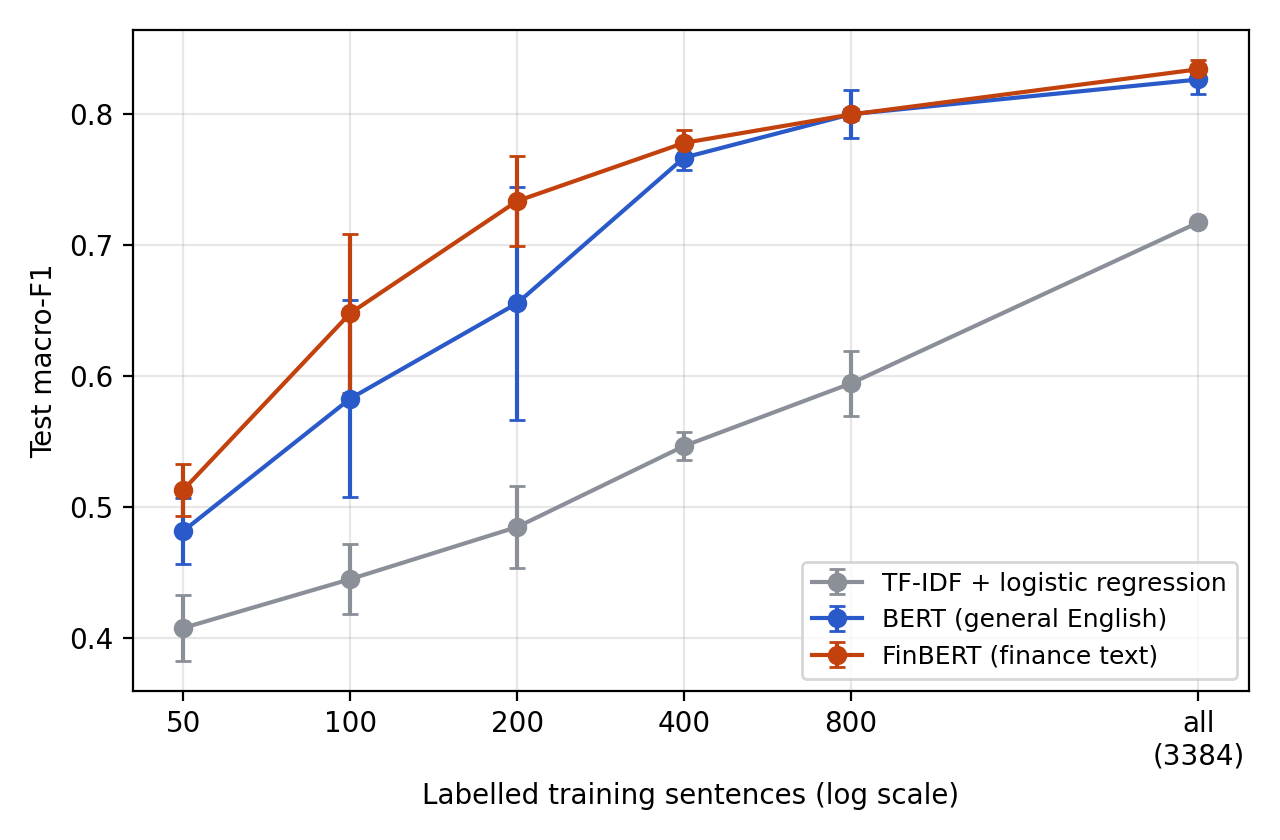

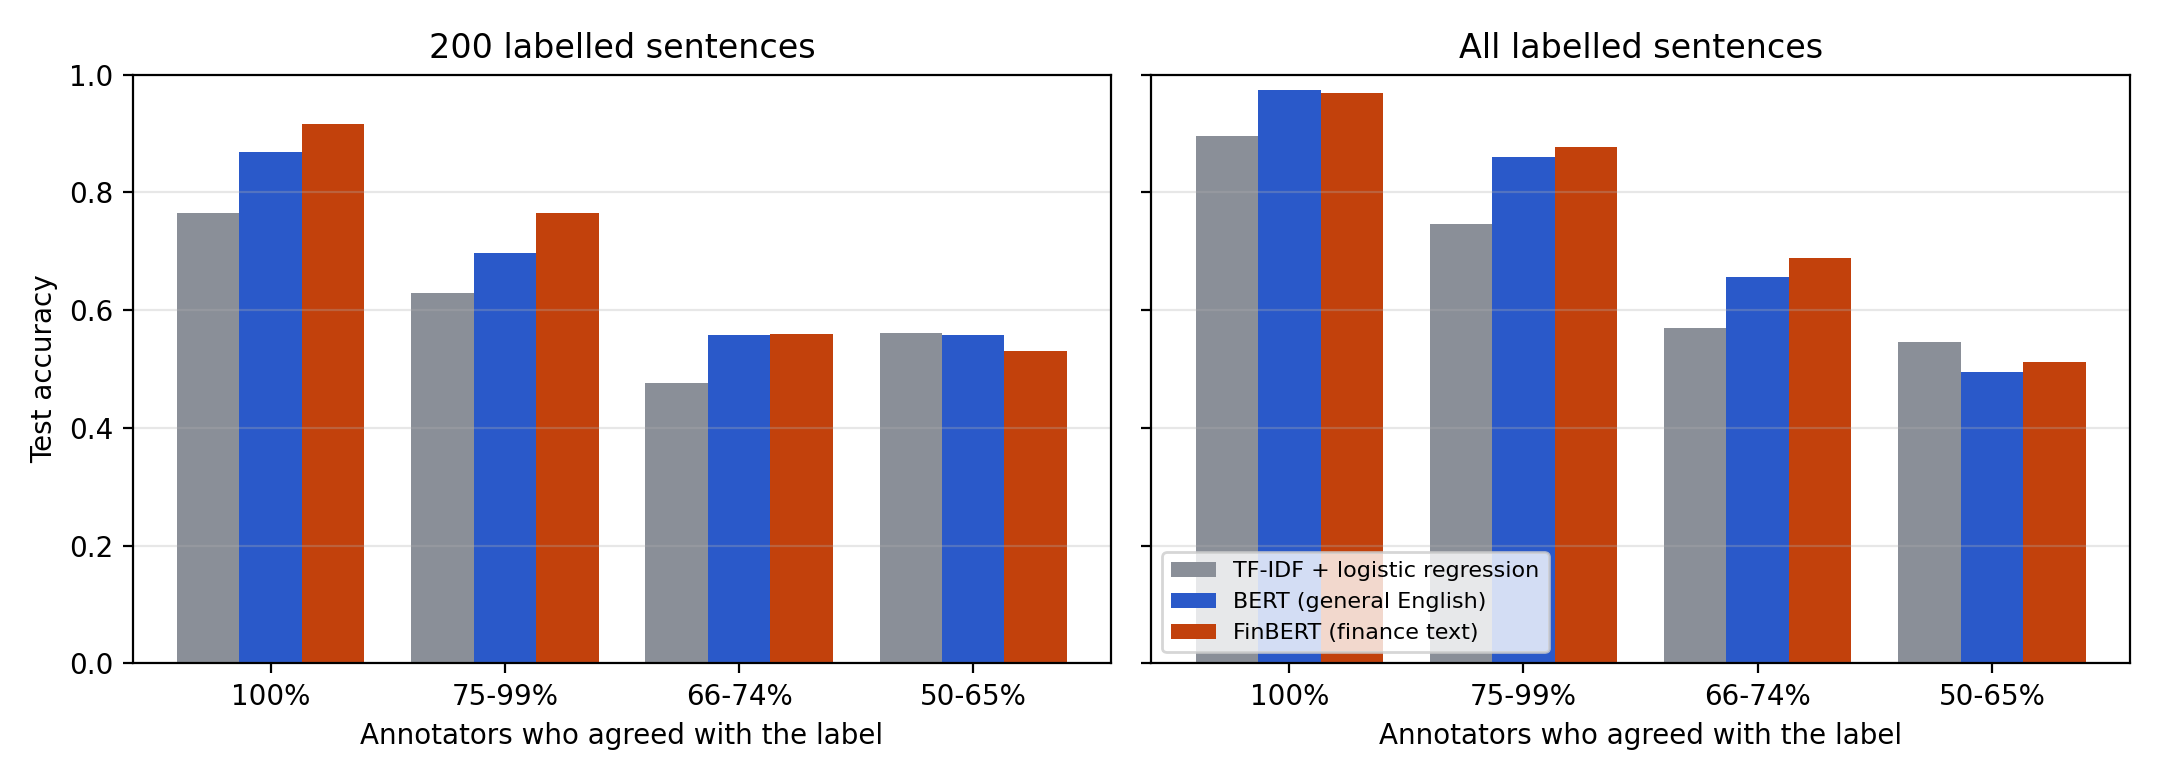

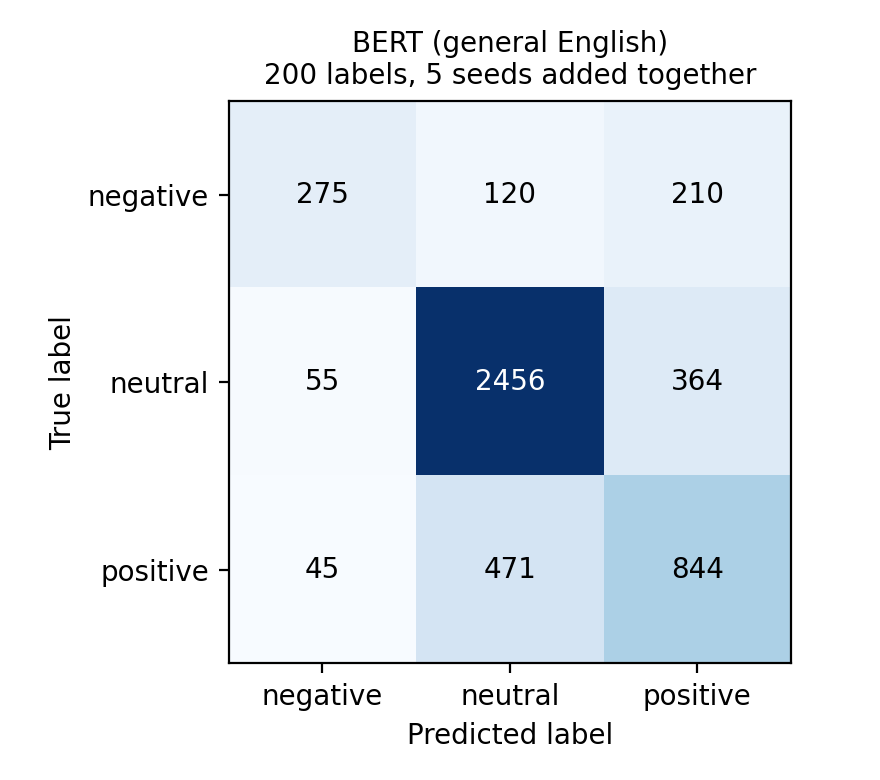

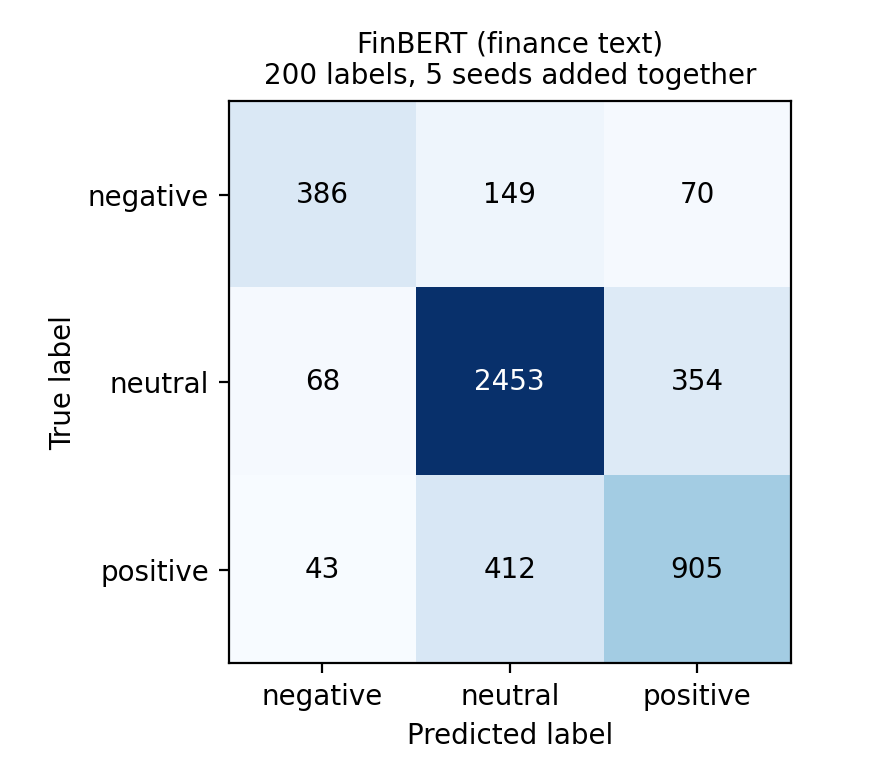

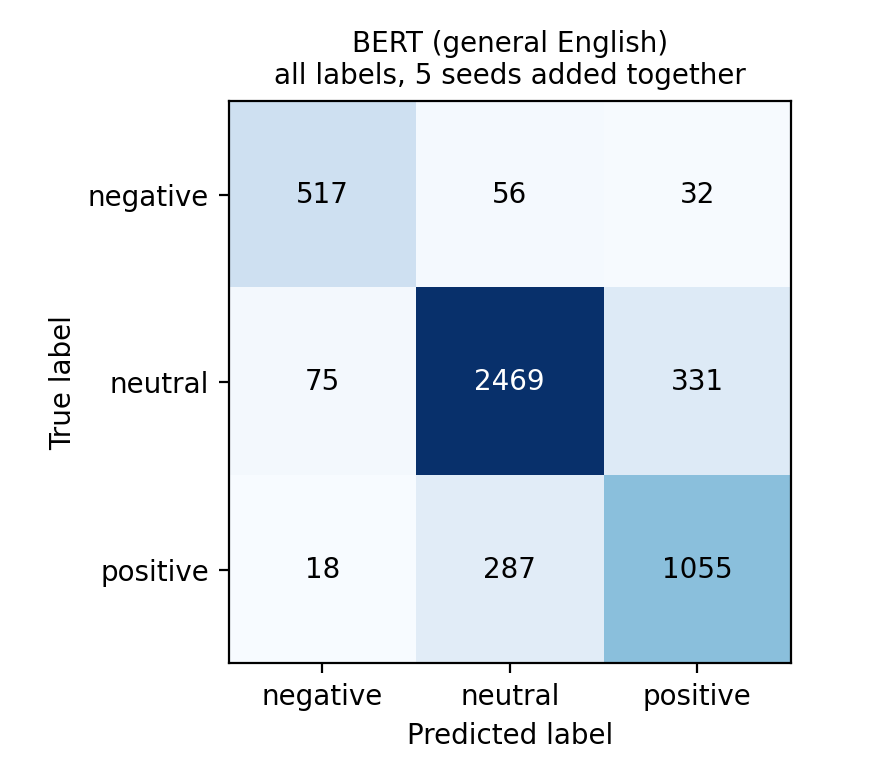

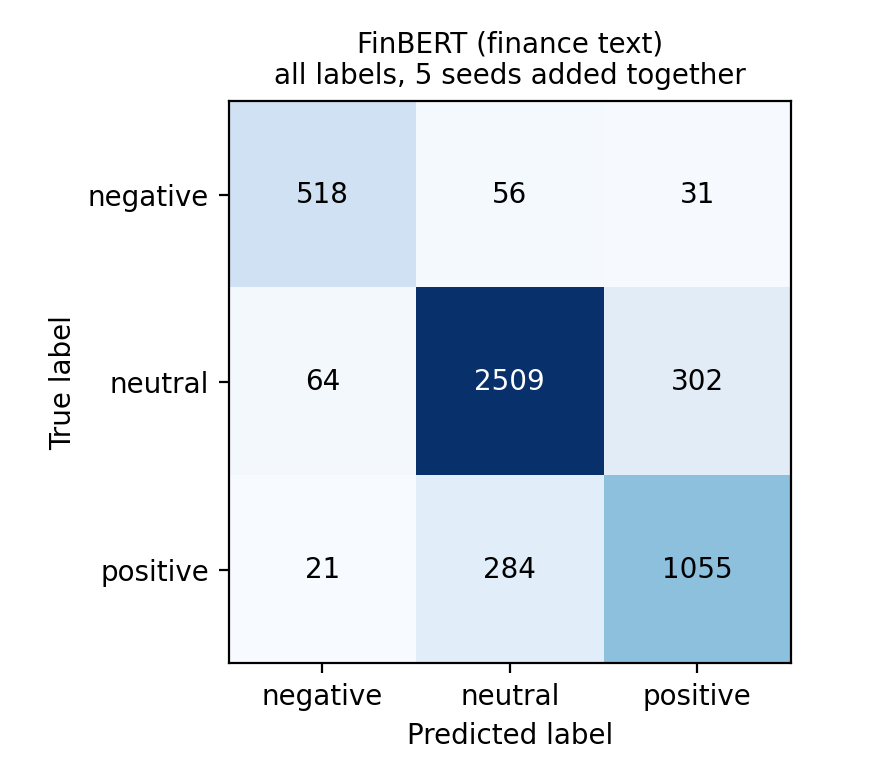

In [ ]:
!python src/analyze.py --results_dir {RESULTS} --figures_dir {FIGURES}

from IPython.display import Image, display
for name in ['learning_curve', 'accuracy_by_agreement',
             'confusion_bert_n200', 'confusion_finbert_n200', 'confusion_bert_nall', 'confusion_finbert_nall']:
    path = f'{FIGURES}/{name}.png'
    if os.path.exists(path):
        display(Image(path))

## Step 5.2 · Robustness check: the first runs at 2e-5

Re-analyse the original 60 runs in `results/`, which used a
learning rate of 2e-5. Checks whether findings
are similar across both learning rates.

Skip this step if `RESULTS` is already set to `'results'`,
since you are already analysing those runs.

In [ ]:
!python src/analyze.py --results_dir results --figures_dir figures

## Step 6 · Read the mistakes

Sentences that FinBERT gets right and general BERT gets wrong in at least 4 of 5 seeds, **at 200 labels**, where the two models differ most. Our group manually read them and sorted them into types by hand, for example finance words that flip meaning ("loss narrowed"), numbers and comparisons, or sentences where the label itself is debatable. Change the filter to `'bert_wins'` or `'both_wrong'` for the other groups, or `n200` to `nall` for the full-data runs. We have included the excel file where this was done in the zip as well for your reference.

In [ ]:
import pandas as pd
pd.set_option('display.max_colwidth', 200)
errors = pd.read_csv(f'{RESULTS}/error_analysis_n200.csv')
print(errors['pattern'].value_counts())
errors[errors['pattern'] == 'finbert_wins'].head(30)

## Save your progress

Downloads `finsent-progress.zip` with the data split, all results and figures, and the exact package versions. Run it whenever you want a backup.

In [ ]:
from google.colab import files
!zip -q -r /content/finsent-progress.zip data results figures results_main figures_main requirements-colab.txt
files.download('/content/finsent-progress.zip')